# EDA on Retail Sales Data
**Track:** Data Analytics | **Level 1 - Task 1**
**Intern:** Mansi Devganiya

## Objective
To perform Exploratory Data Analysis on retail sales data in order to uncover sales trends, customer behaviour and product performance, and to provide actionable business recommendations.

**Dataset:** Retail Sales Dataset (Kaggle), 1,000 transactions, Jan 2023 - Jan 2024
**Tools:** Python, pandas, matplotlib, seaborn

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

## 1. Data Loading and Initial Inspection
First, we load the dataset and check its shape, data types, missing values and duplicates.

In [18]:
df = pd.read_csv("retail_sales_dataset.csv")

print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nNull values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.head()

Shape: (1000, 9)

Data types:
 Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object

Null values:
 Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate rows: 0


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


**Observations:**
- The dataset contains 1,000 rows and 9 columns.
- There are no missing values and no duplicate rows, so no cleaning is required.
- The `Date` column is stored as text, so it will be converted to datetime format.
- The dataset has no product name column, only 3 product categories: Beauty, Clothing and Electronics.

## 2. Descriptive Statistics
Mean, median, mode and standard deviation of all numerical columns.

In [6]:
num_cols = df.select_dtypes(include="number").drop(columns=["Transaction ID"])

stats = pd.DataFrame({
    "Mean": num_cols.mean(),
    "Median": num_cols.median(),
    "Mode": num_cols.mode().iloc[0],
    "Std Dev": num_cols.std()
}).round(2)
stats

,Mean,Median,Mode,Std Dev
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


In [7]:
print("Skewness of Total Amount:", round(df["Total Amount"].skew(), 2))

Skewness of Total Amount: 1.38


**Observations:**
- The mean of Total Amount (456.00) is much higher than its median (135.00), which indicates that the distribution is right skewed (skewness = 1.38).
- The standard deviation (560.00) is larger than the mean, showing high variation in transaction values.
- The average customer age is 41.4 years, and the typical order has 2 to 3 items (mean quantity = 2.51).

## 3. Time Series Analysis
Analysing monthly and quarterly sales trends.

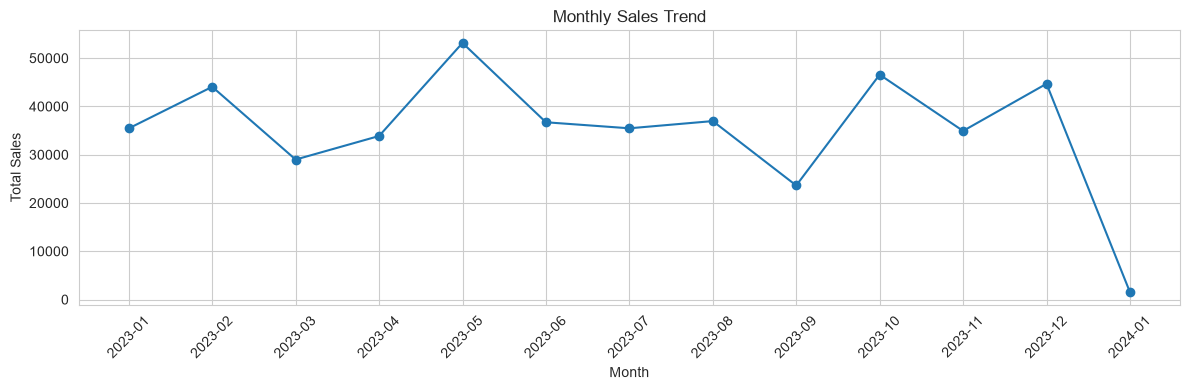

In [8]:
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")

monthly = df.groupby("Month")["Total Amount"].sum()
monthly.index = monthly.index.astype(str)

plt.figure(figsize=(12,4))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

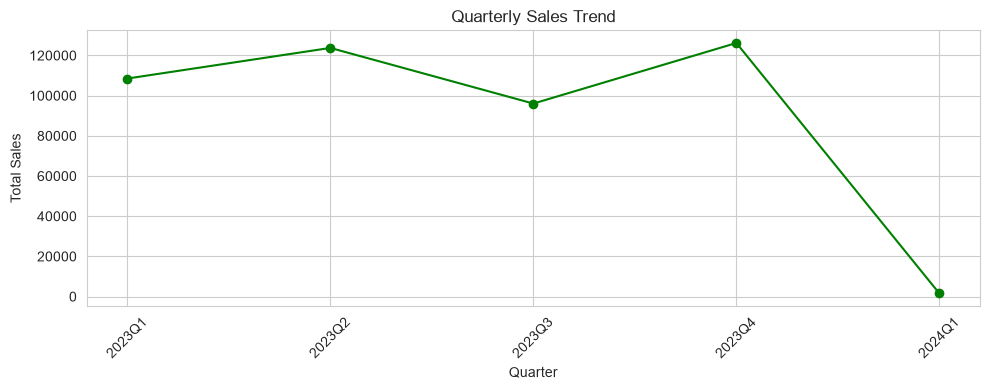

In [9]:
quarterly = df.groupby("Quarter")["Total Amount"].sum()
quarterly.index = quarterly.index.astype(str)

plt.figure(figsize=(10,4))
plt.plot(quarterly.index, quarterly.values, marker="o", color="green")
plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
print("Highest month  :", monthly.idxmax(), monthly.max())
print("Lowest full month:", monthly.iloc[:-1].idxmin(), monthly.iloc[:-1].min())
print("Highest quarter:", quarterly.idxmax(), quarterly.max())
print("Lowest full quarter:", quarterly.iloc[:-1].idxmin(), quarterly.iloc[:-1].min())

Highest month  : 2023-05 53150
Lowest full month: 2023-09 23620
Highest quarter: 2023Q4 126190
Lowest full quarter: 2023Q3 96045


**Observations:**
- Monthly sales peaked in May 2023 (53,150) and were lowest in September 2023 (23,620) among the full months. January 2024 contains only one day of data, so it should be ignored when comparing months.
- Q4 2023 was the strongest quarter (126,190) and Q3 2023 was the weakest (96,045).
- Sales are volatile from month to month, with no clear upward or downward trend over 2023.
- Sales recover strongly in October (46,580) and December (44,690), which suggests a year-end buying pattern.

## 4. Customer Demographics Analysis
Distribution of sales by gender and age group.


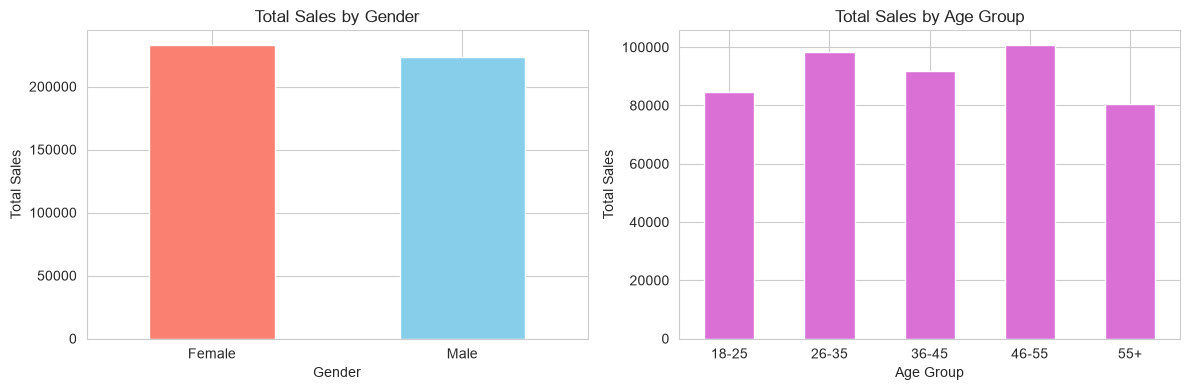

In [11]:
df["Age Group"] = pd.cut(df["Age"],
                         bins=[17, 25, 35, 45, 55, 100],
                         labels=["18-25", "26-35", "36-45", "46-55", "55+"])

fig, ax = plt.subplots(1, 2, figsize=(12,4))

df.groupby("Gender")["Total Amount"].sum().plot(kind="bar", ax=ax[0], color=["salmon", "skyblue"])
ax[0].set_title("Total Sales by Gender")
ax[0].set_ylabel("Total Sales")
ax[0].tick_params(axis="x", rotation=0)

df.groupby("Age Group", observed=True)["Total Amount"].sum().plot(kind="bar", ax=ax[1], color="orchid")
ax[1].set_title("Total Sales by Age Group")
ax[1].set_ylabel("Total Sales")
ax[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [12]:
print("Sales share by gender (%):\n",
      (df.groupby("Gender")["Total Amount"].sum() / df["Total Amount"].sum() * 100).round(1))
print("\nSales share by age group (%):\n",
      (df.groupby("Age Group", observed=True)["Total Amount"].sum() / df["Total Amount"].sum() * 100).round(1))
print("\nAverage order value by age group:\n",
      df.groupby("Age Group", observed=True)["Total Amount"].mean().round(1))

Sales share by gender (%):
 Gender
Female    51.1
Male      48.9
Name: Total Amount, dtype: float64

Sales share by age group (%):
 Age Group
18-25    18.5
26-35    21.6
36-45    20.1
46-55    22.1
55+      17.6
Name: Total Amount, dtype: float64

Average order value by age group:
 Age Group
18-25    500.3
26-35    480.4
36-45    454.8
46-55    439.7
55+      412.4
Name: Total Amount, dtype: float64


**Observations:**
- Female customers contribute 51.1% of total sales and male customers 48.9%, so both genders are almost equally important.
- The 46-55 age group contributes the highest sales (22.1%), followed by 26-35 (21.6%). The 55+ group contributes the least (17.6%).
- The average order value falls steadily with age, from 500.3 for customers aged 18-25 to 412.4 for customers aged 55+. Younger customers spend more per order.

## 5. Product Analysis
The dataset has no product names, so each combination of Product Category and Price per Unit is treated as a product tier. The top 10 tiers are shown below, followed by revenue by category.

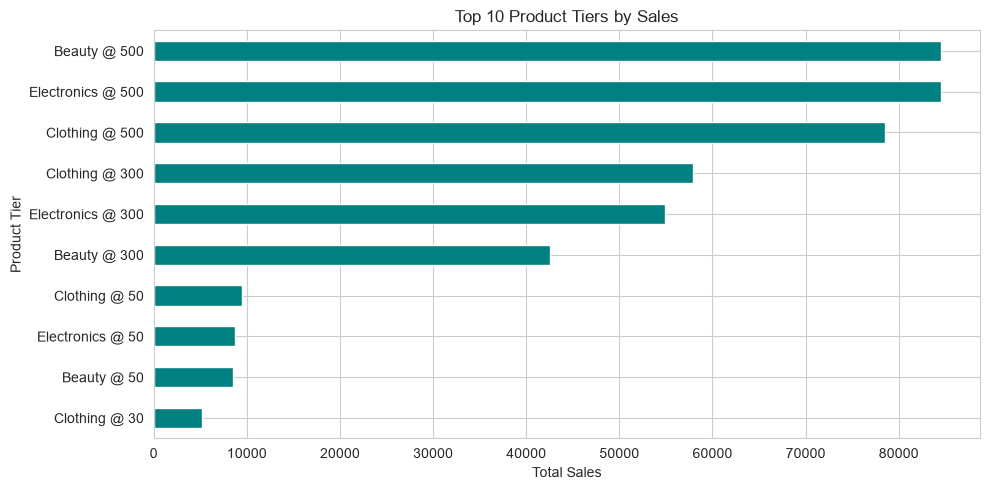

In [13]:
df["Product Tier"] = df["Product Category"] + " @ " + df["Price per Unit"].astype(str)

top10 = df.groupby("Product Tier")["Total Amount"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
top10.sort_values().plot(kind="barh", color="teal")
plt.title("Top 10 Product Tiers by Sales")
plt.xlabel("Total Sales")
plt.tight_layout()
plt.show()

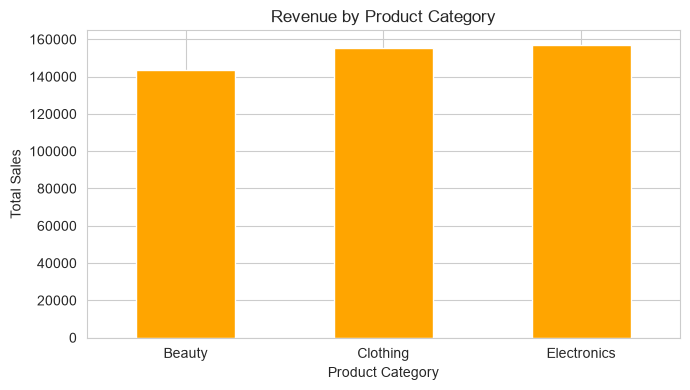

In [14]:
plt.figure(figsize=(7,4))
df.groupby("Product Category")["Total Amount"].sum().plot(kind="bar", color="orange")
plt.title("Revenue by Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [15]:
print("Top 3 tiers:\n", top10.head(3))
print("\nTop 10 share of total sales (%):", round(top10.sum() / df["Total Amount"].sum() * 100, 1))
print("\nCategory revenue:\n", df.groupby("Product Category")["Total Amount"].sum())
print("\nCategory share (%):\n",
      (df.groupby("Product Category")["Total Amount"].sum() / df["Total Amount"].sum() * 100).round(1))

Top 3 tiers:
 Product Tier
Beauty @ 500         84500
Electronics @ 500    84500
Clothing @ 500       78500
Name: Total Amount, dtype: int64

Top 10 share of total sales (%): 95.3

Category revenue:
 Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64

Category share (%):
 Product Category
Beauty         31.5
Clothing       34.1
Electronics    34.4
Name: Total Amount, dtype: float64


**Observations:**
- Beauty @ 500 and Electronics @ 500 are the top product tiers, each with total sales of 84,500, followed by Clothing @ 500 (78,500).
- The top 10 tiers together account for about 95.3% of total sales, so revenue is concentrated in a few high-priced tiers.
- Electronics generates the highest revenue (156,905, 34.4%), followed by Clothing (155,580, 34.1%) and Beauty (143,515, 31.5%). The three categories are close, but Beauty is the weakest.

## 6. Correlation Heatmap
Relationship between the numerical variables.

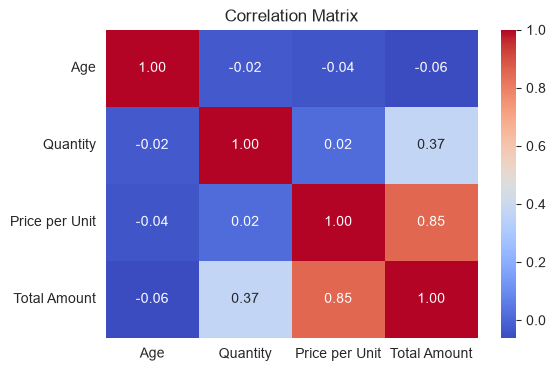

In [16]:
corr = df[["Age", "Quantity", "Price per Unit", "Total Amount"]].corr()

plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

**Observations:**
- Total Amount has a very strong positive correlation with Price per Unit (0.85), so price is the main driver of sales value.
- Total Amount has a moderate positive correlation with Quantity (0.37).
- Age has an almost zero correlation with all other variables (between -0.02 and -0.06), so age alone does not explain spending behaviour.

## 7. Additional Analysis: High-Price vs Low-Price Items
Checking how much revenue is generated by premium items (price per unit of 300 or more) compared with low-price items.

             count     sum  % of transactions  % of revenue
Price Tier                                                 
High (300+)    396  402900               39.6          88.4
Low (<300)     604   53100               60.4          11.6


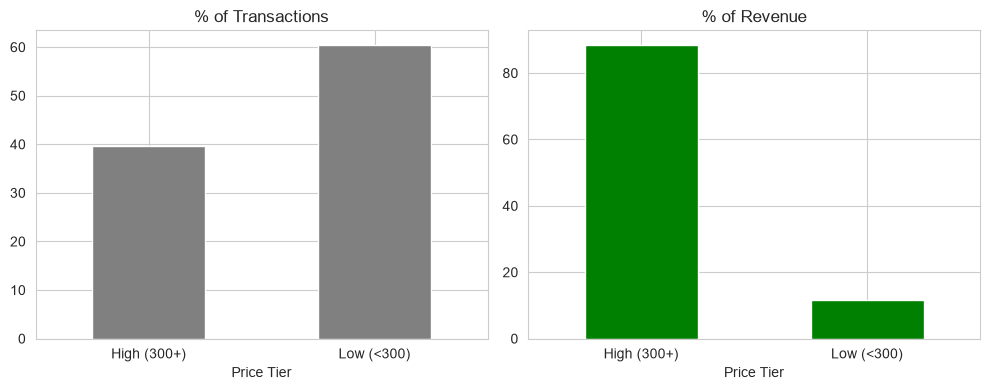

In [17]:
df["Price Tier"] = np.where(df["Price per Unit"] >= 300, "High (300+)", "Low (<300)")

tier = df.groupby("Price Tier")["Total Amount"].agg(["count", "sum"])
tier["% of transactions"] = (tier["count"] / tier["count"].sum() * 100).round(1)
tier["% of revenue"] = (tier["sum"] / tier["sum"].sum() * 100).round(1)
print(tier)

fig, ax = plt.subplots(1, 2, figsize=(10,4))
tier["% of transactions"].plot(kind="bar", ax=ax[0], color="gray")
ax[0].set_title("% of Transactions")
ax[0].tick_params(axis="x", rotation=0)
tier["% of revenue"].plot(kind="bar", ax=ax[1], color="green")
ax[1].set_title("% of Revenue")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Observation:** High-priced items (300 and above) make up only 39.6% of transactions but generate 88.4% of total revenue. Low-priced items make up 60.4% of transactions but only 11.6% of revenue. This is a non-obvious insight: transaction volume alone is misleading, and premium products drive the business.

## 8. Conclusion and Recommendations
**Key findings:**
- Total sales of about 456,000 came from 1,000 transactions, with an average order value of 456 and a median of only 135 (right-skewed).
- Sales are volatile across months, with a peak in May 2023 and a strong Q4.
- Female and male customers spend almost equally, and younger customers have a higher average order value.
- Price per Unit is the main driver of revenue: premium items give 88.4% of revenue from 39.6% of transactions.

**Recommendations:**
1. **Focus on premium products:** Promote and stock high-priced items (300+) more, since they generate most of the revenue. Bundle low-priced items with premium ones to increase order value.
2. **Target younger customers and plan seasonally:** Customers aged 18-35 have higher average order values, so campaigns should target them. Increase inventory and marketing before October-December, and investigate why Q3 (especially September) is weak.
3. **Grow the Beauty category:** Beauty is the lowest revenue category (31.5%). Targeted offers and cross-selling with Clothing and Electronics could close the gap.